# Metal particles of thousands of atoms

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/24_metal_particles.ipynb)

A metal nanoparticle is neither a molecule nor a crystal. It has no cell and no periodic
directions, and it can hold thousands of atoms. The **periodic autocorrelation** of the crystal
notebooks describes it all the same: it sums the products of the field weights of every pair of
atoms closer than a cutoff, binned by their distance. With open boundaries it needs no cell, and
the number of such pairs grows linearly with the number of atoms. The **overlap kernel** compares
every atom of one structure with every atom of another, so its cost grows with the square.

The notebook asks three questions.

1. How does the cost of each description grow with the size of a particle?
2. How well does the autocorrelation predict a property of 150 particles of six metals? The
   target is the energy per atom from the effective medium theory potential (EMT) of ASE, for
   unrelaxed particles of 13 to 3,564 atoms.
3. The reference: an EMT energy is a sum over the atoms of a function of each atom's neighbours,
   and the autocorrelation reads the same pair distances. Does it predict better than a linear
   regression on the numbers of neighbours in the first shells of the lattice?

Everything is computed live: the particles are built by ASE and their energies by EMT. Running
time: one to two minutes.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## How the cost grows

The cell builds copper icosahedra of 147 to 2,869 atoms and times the autocorrelation of each.
A training kernel of 100 such particles needs 100 autocorrelations, but 5,050 overlaps of two
particles. The time of one such overlap is read from the stored runs
(`benchmarks/run_particles.py --stage scaling`).

In [2]:
import json
import time
import warnings

import numpy as np
from ase.cluster import Icosahedron

sys.path.insert(0, "benchmarks")
import run_particles as RP                      # the benchmark script of item NT2
from cmfqsar.periodic import OVERLAP_ATOM_LIMIT, crystal_table, inorganic_fieldset, periodic_feature_matrix

warnings.filterwarnings("ignore")
with open("benchmarks/results/particles/scaling.json", encoding="utf-8") as fh:
    stored = {r["atoms"]: r for r in json.load(fh)["rows"] if r["kind"] == "cluster"}

fs = inorganic_fieldset(["Cu"], physchem=RP.PHYSCHEM)


def particle_of(shells):
    p = Icosahedron("Cu", shells)
    p.center(vacuum=8.0)
    p.pbc = False
    return p


periodic_feature_matrix(crystal_table([particle_of(2)], fs, ["p"]).molecules, RP.SPEC)   # warm-up
print("one particle, and a training kernel of 100 particles of that size (5,050 pairs of particles)")
print("%8s %22s %24s %26s" % ("atoms", "autocorrelation, s", "100 particles, s", "overlap kernel, 100, min"))
for shells in (4, 6, 8, 10):
    particle = particle_of(shells)
    start = time.perf_counter()
    periodic_feature_matrix(crystal_table([particle], fs, ["p"]).molecules, RP.SPEC)
    seconds = time.perf_counter() - start
    pair = stored[len(particle)]["overlap_pair_seconds"]          # one pair of particles, stored
    print("%8d %22.3f %24.1f %26.1f" % (len(particle), seconds, 100 * seconds, 5050 * pair / 60))
print()
print("the model refuses the overlap kernel above %d atoms per structure" % OVERLAP_ATOM_LIMIT)

one particle, and a training kernel of 100 particles of that size (5,050 pairs of particles)
   atoms     autocorrelation, s         100 particles, s   overlap kernel, 100, min
     147                  0.006                      0.6                        0.0
     561                  0.034                      3.4                        0.6
    1415                  0.118                     11.8                        7.6


    2869                  0.293                     29.3                       28.0

the model refuses the overlap kernel above 2000 atoms per structure


The stored runs time the same two steps on copper icosahedra of 55 to several thousand atoms.
On a logarithmic scale a power law is a straight line, and its exponent is the slope. The text
after the figure gives the exponents the benchmark fits. The first overlap time, at 55 atoms,
includes the set-up of the first call and is not drawn.

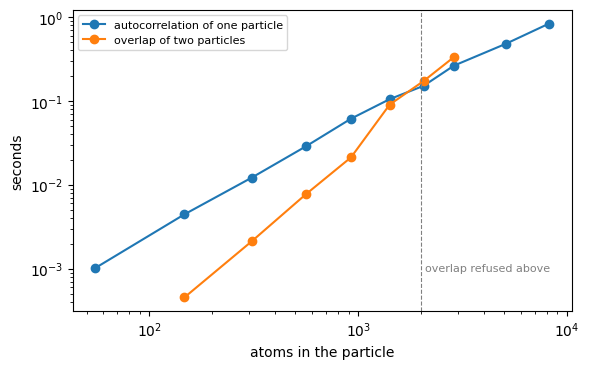

In [3]:
import matplotlib.pyplot as plt

with open("benchmarks/results/particles/scaling.json", encoding="utf-8") as fh:
    rows_t = sorted((r for r in json.load(fh)["rows"] if r["kind"] == "cluster"), key=lambda r: r["atoms"])
n_t = np.array([r["atoms"] for r in rows_t], float)
fig, ax = plt.subplots(figsize=(6, 3.8))
for key, label in (("autocorrelation_seconds", "autocorrelation of one particle"),
                   ("overlap_pair_seconds", "overlap of two particles")):
    t = np.array([r.get(key) if r.get(key) is not None else np.nan for r in rows_t], float)
    ok = np.isfinite(t) & (t > 0)
    if key == "overlap_pair_seconds":
        ok &= n_t > n_t.min()                     # the first call includes its set-up
    ax.loglog(n_t[ok], t[ok], "o-", label=label)
ax.axvline(OVERLAP_ATOM_LIMIT, color="grey", ls="--", lw=0.8)
ax.text(OVERLAP_ATOM_LIMIT * 1.05, ax.get_ylim()[0] * 3, "overlap refused above", fontsize=8, color="grey")
ax.set_xlabel("atoms in the particle")
ax.set_ylabel("seconds")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

The autocorrelation of one particle takes a fraction of a second at every size, and its time
grows about linearly with the number of atoms. A training kernel of 100 particles of 2,869 atoms
needs 28 seconds of autocorrelation, and 28 *minutes* of overlap kernel at one field width. The
stored runs give the exponents of the growth: 1.24 for the autocorrelation and 2.38 for the
overlap kernel. The neighbour list used before this item grew with exponent 2.0, and at 5,083
atoms it needed 5.4 GB of memory.

So the model refuses the overlap kernel for a structure of more than 2,000 atoms
(`CMFModel.max_overlap_atoms`; `None` turns the guard off, and molecules are never refused). For
particles the autocorrelation is the description that scales.

## A property of 150 particles

The set holds icosahedra, decahedra and truncated octahedra of Cu, Ag, Au, Ni, Pd and Pt, 25 of
each metal, built on the bulk lattice and not relaxed. The target is the EMT energy per atom.
Four models are compared, with 5-fold cross-validation repeated with five seeds, and then trained
on the particles of at most 1,000 atoms to predict the 54 larger ones.

- **size law**: a linear regression on n<sup>-1/3</sup> (n the number of atoms), with its own
  intercept and slope for each metal. For a compact particle n<sup>-1/3</sup> is proportional to
  the fraction of atoms at the surface.
- **autocorrelation**: kernel ridge regression on the cosine-normalised autocorrelation of two
  fields (steric and electronegativity), cutoff 8 Å.
- **shell counts**: a linear regression on the number of neighbour pairs per atom in each of the
  first four neighbour shells of the bulk lattice, with its own coefficients for each metal. The
  number of shells was fixed before the first run: the cutoff of EMT lies between the third and
  the fourth shell.
- **coordination histogram**: the same on the fraction of atoms with each number of nearest
  neighbours, from 0 to 12.

The ridge of every kernel model is chosen by an inner cross-validation in each training part.

In [4]:
start = time.time()
particles = RP.particle_set()
y = RP.energies(particles)                       # EMT energy per atom, eV
metal = np.array([p.get_chemical_symbols()[0] for p in particles])
atoms = np.array([len(p) for p in particles], float)
names = [p.info["name"] for p in particles]
print("%d particles, %d to %d atoms; energy per atom %.2f to %.2f eV"
      % (len(y), atoms.min(), atoms.max(), y.min(), y.max()))

fields = inorganic_fieldset(list(RP.METALS), physchem=RP.PHYSCHEM)
K = RP._cosine(periodic_feature_matrix(crystal_table(particles, fields, names).molecules, RP.SPEC))
kernels = {"autocorrelation": K,
           "shell counts": RP.per_metal_kernel(metal, RP.shell_counts(particles)),
           "coordination histogram": RP.per_metal_kernel(metal, RP.coordination_histogram(particles))}

from cmfqsar.model import _cv_splits
rmse = {m: [] for m in ["size law", *kernels]}
mean_pred = {m: np.zeros(len(y)) for m in kernels}
for seed in RP.SEEDS:
    pred = {m: np.full(len(y), np.nan) for m in rmse}
    for test, train in _cv_splits(y, 5, seed):
        pred["size law"][test] = RP._size_law(metal, atoms, y, train, test)
        for m, Km in kernels.items():
            pred[m][test] = RP._krr_inner(Km, y, train, test, seed)
    for m in rmse:
        rmse[m].append(1000 * np.sqrt(np.mean((pred[m] - y) ** 2)))
    for m in kernels:
        mean_pred[m] += pred[m] / len(RP.SEEDS)

train = np.flatnonzero(atoms <= RP.SPLIT_ATOMS)
test = np.flatnonzero(atoms > RP.SPLIT_ATOMS)
far = {"size law": RP._size_law(metal, atoms, y, train, test)}
far.update({m: RP._krr_inner(Km, y, train, test, 0) for m, Km in kernels.items()})

print()
print("%-24s %22s %26s %20s" % ("model", "cross-validation, meV", "larger particles, meV", "largest error, meV"))
for m in rmse:
    print("%-24s %16.1f (%.1f) %26.1f %20.1f" % (m, np.mean(rmse[m]), np.std(rmse[m]),
          1000 * np.sqrt(np.mean((far[m] - y[test]) ** 2)), 1000 * np.max(np.abs(far[m] - y[test]))))
print()
print("RMSE of a reference minus that of the autocorrelation [95 % interval over particles]:")
for m in ("shell counts", "coordination histogram"):
    a = RP._boot_rmse_difference(y, mean_pred[m], mean_pred["autocorrelation"])
    b = RP._boot_rmse_difference(y[test], far[m], far["autocorrelation"])
    print("  %-24s cross-validation %+.1f [%+.1f, %+.1f]   larger particles %+.1f [%+.1f, %+.1f]"
          % (m, a["mean"], a["lo"], a["hi"], b["mean"], b["lo"], b["hi"]))

with open("benchmarks/results/particles/counts.json", encoding="utf-8") as fh:
    counts = json.load(fh)
same = all(abs(np.mean(rmse[m]) - counts["cv"][m]["rmse_mev"]) < 1e-9 for m in kernels)
print()
print("the live numbers repeat the stored ones:", same, "(%.0f s)" % (time.time() - start))

150 particles, 13 to 3564 atoms; energy per atom 0.08 to 1.17 eV



model                     cross-validation, meV      larger particles, meV   largest error, meV
size law                             44.9 (2.3)                       36.2                 92.7
autocorrelation                      26.3 (2.0)                       26.1                 76.0
shell counts                         29.2 (4.3)                       15.0                 35.9
coordination histogram               95.4 (8.3)                       31.8                 65.0

RMSE of a reference minus that of the autocorrelation [95 % interval over particles]:
  shell counts             cross-validation +2.4 [-8.3, +13.0]   larger particles -11.1 [-17.4, -4.8]
  coordination histogram   cross-validation +61.9 [+39.5, +83.3]   larger particles +5.7 [-1.6, +13.1]

the live numbers repeat the stored ones: True (19 s)


The first picture shows three particles of the set, one of each shape, with every atom
coloured by its number of neighbours: surface atoms have fewer neighbours than the atoms inside,
and atoms at edges and corners fewer still.

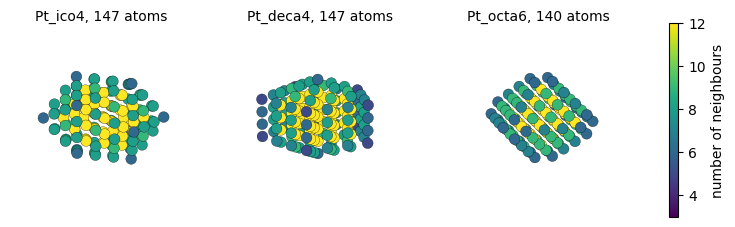

In [5]:
from cmfqsar.periodic import coordination_numbers

shown = [next(p for p in particles if p.info["name"] == name)
         for name in ("Pt_ico4", "Pt_deca4", "Pt_octa6")]
fig = plt.figure(figsize=(10, 3.6))
for j, p in enumerate(shown):
    ax = fig.add_subplot(1, 3, j + 1, projection="3d")
    cn = coordination_numbers(p)
    pts = ax.scatter(*p.get_positions().T, c=cn, cmap="viridis", vmin=3, vmax=12, s=60,
                     edgecolors="black", linewidths=0.2, depthshade=False)
    ax.set_title("%s, %d atoms" % (p.info["name"], len(p)), fontsize=10)
    ax.set_axis_off()
    ax.view_init(elev=15, azim=30)
fig.colorbar(pts, ax=fig.axes, shrink=0.7, label="number of neighbours")
plt.show()

The second picture plots the predictions against the EMT energy per atom. Left: cross-validation
(the mean over the five seeds). Right: the model trained on the particles of at most 1,000 atoms,
predicting the larger ones, for the autocorrelation and for the shell counts.

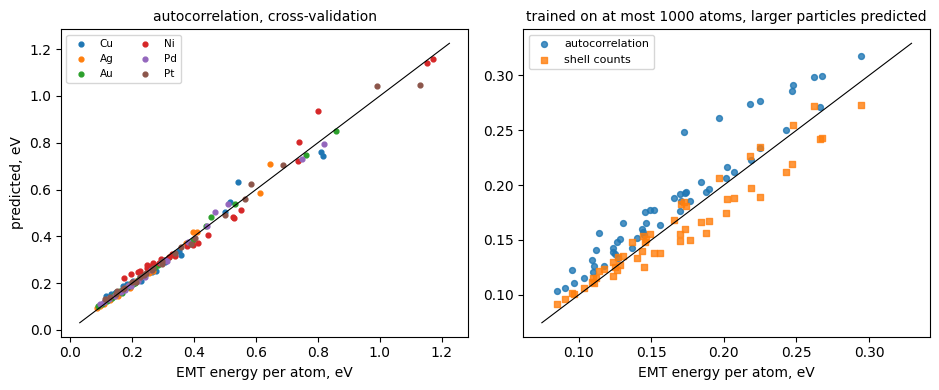

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for el in RP.METALS:
    m = metal == el
    axes[0].scatter(y[m], mean_pred["autocorrelation"][m], s=12, label=el)
axes[0].set_title("autocorrelation, cross-validation", fontsize=10)
axes[0].legend(fontsize=7.5, ncol=2)
for name, marker in (("autocorrelation", "o"), ("shell counts", "s")):
    axes[1].scatter(y[test], far[name], s=18, marker=marker, alpha=0.8, label=name)
axes[1].set_title("trained on at most %d atoms, larger particles predicted" % RP.SPLIT_ATOMS, fontsize=10)
axes[1].legend(fontsize=8)
for ax in axes:
    lims = [min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
    ax.plot(lims, lims, color="black", lw=0.8)
    ax.set_xlabel("EMT energy per atom, eV")
axes[0].set_ylabel("predicted, eV")
plt.tight_layout()
plt.show()

**The autocorrelation predicts well.** It reaches 26 meV per atom in cross-validation, against 45
meV for the size law, on a target that spans more than 1 eV. Trained on the particles of at most
1,000 atoms, it predicts the larger ones to 26 meV. So the description of a particle works, and it
extrapolates in size.

**But counting neighbours does as well, and extrapolates better.** The shell counts reach 29 meV
in cross-validation, and the interval of the difference contains zero (+2.4 [-8.3, +13.0] meV).
On the larger particles they reach 15 meV, against 26 meV: better by 11 meV, with the interval
below zero. Their largest error there is 36 meV, against 76 meV.

The reason is the target. An EMT energy is a sum over the atoms of a function of the neighbours
of each atom, and on an unrelaxed particle the neighbours sit exactly on the shells of the bulk
lattice. Four numbers per particle then hold almost all that the energy depends on. The
autocorrelation reads the same pair distances, but smoothed by Gaussians of 0.5 Å, mixed over two
fields and divided by its own length (the cosine normalisation). It recovers most of the
information, but not all, and the loss shows when the model has to extrapolate. Which of these
steps loses it was not tested.

The coordination histogram, which counts only the nearest neighbours of each atom, does worse in
cross-validation (95 meV). It has 13 fractions per metal and only about 20 training particles
per metal, which is the likely reason. On the larger particles it reaches 32 meV.

So on this set the fields of the autocorrelation are a fair description of a particle, but they
are not needed. A property that depends on more than the counts of neighbours, for example a
relaxed structure, a mixed composition or a measured property, could change that. It was not
tested here.

## What to take from this notebook

- A particle needs no cell. The periodic autocorrelation with open boundaries describes it, and
  its cost grows about linearly with the number of atoms. The overlap kernel grows with the
  square, and the model refuses it above 2,000 atoms per structure.
- On 150 unrelaxed metal particles the autocorrelation predicts the EMT energy per atom to 26
  meV, far better than the size law.
- A regression on the numbers of neighbours in four lattice shells does as well in
  cross-validation and better on larger particles. When the target is built from neighbour
  counts, count the neighbours first.
- The rule of the earlier notebooks holds for particles too: before a field model is credited,
  give the one-number version of what it reads, here the counts of the neighbour shells, the same
  folds and the same choice of settings.

From the command line, the benchmark of this notebook:

```
python benchmarks/run_particles.py --stage scaling --stage property --stage counts
```

Where to read further in the manual: *Crystals and other periodic structures* explains how
particles, sheets and tubes are read from CIF, POSCAR, extended XYZ and ASE databases, and has the
neighbour list, the guard of the overlap kernel and the measurements of this notebook.